# Воспроизведение смешивания тренда, сезонности и шума в DecoVAE-FM

Источник: `notebooks/debug_training.ipynb`, особенно ячейки с `core.encode` и
`decoded_trend / decoded_seasonal / decoded_logvar`. Используется **текущий код из
`decovaefm`**, а не отдельная реализация архитектуры.

Порядок: исходный DummyRandomDataset → декомпозиция до обучения → обучение с параметрами
исходного ноутбука → декомпозиция и декодеры после обучения → контрольные сигналы
с известными компонентами → зависимость утечки от периода.

В репозитории нет сохранённых весов исходного запуска и seed инициализации модели.
Поэтому воспроизводим тип поведения, а не конкретные исторические кривые.
По умолчанию выполняется полный повтор: **30 эпох, 2048 train / 256 val, контекст 512,
горизонт 256, learning_rate=0.001, kl_weight=1**. На CPU это может занять несколько минут.
Для проверки существующих весов задайте `CHECKPOINT_PATH`; для короткой проверки задайте
`RUN_PROFILE="smoke"` (это не полный эксперимент).

In [1]:
import os
import sys
import json
import hashlib
import inspect
import platform
import subprocess
import time
from pathlib import Path
from copy import deepcopy
from unittest.mock import patch

# Работает и из корня проекта, и из notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "decovaefm" / "models" / "decovae_fm.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Запустите ноутбук из корня DecoVAE_fm_project или notebooks/.")
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import lightning as L
from IPython.display import display, Markdown
from torch.utils.data import DataLoader
from types import SimpleNamespace
from omegaconf import OmegaConf
from decovaefm.debug_data import DummyRandomDataset
from decovaefm.lightning_module import DecoVAEFMLightning

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})

RUN_PROFILE = "full"                  # "full" или "smoke"
CHECKPOINT_PATH = None                # Например ROOT / "outputs/.../epoch_29.ckpt"
SAVE_CHECKPOINT = False               # При True: outputs/decomposition_reproduction/current.ckpt
SEED = 42
DATA_SEED = 1
MC_SAMPLES = 100
# Complex FFT/attention проверяем на CPU; CUDA тоже поддерживается. MPS не выбираем.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(min(4, os.cpu_count() or 1))
L.seed_everything(SEED, workers=True)

config_files = [ROOT / "configs" / group / "default.yaml" for group in ["data", "model", "trainer"]]
args = SimpleNamespace(**OmegaConf.to_container(OmegaConf.merge(*[OmegaConf.load(p) for p in config_files]), resolve=True))
args.pred_len = 256
args.load_seed = DATA_SEED
args.debug_on_dummy = True
args.epochs = 30
args.learning_rate = 0.001
args.kl_weight = 1.0
args.devices = 1
args.accelerator = "gpu" if DEVICE == "cuda" else "cpu"
args.viz_enabled = False
if RUN_PROFILE not in {"full", "smoke"}:
    raise ValueError("RUN_PROFILE must be full or smoke")
N_TRAIN, N_VAL = (2048, 256) if RUN_PROFILE == "full" else (128, 32)
if RUN_PROFILE == "smoke":
    args.epochs = 2
T, H = args.context_len, args.pred_len
# Ограничение текущего fold: выбираем согласованные длины патчей/окон.
assert args.patch_size == args.stride and T % args.stride == H % args.stride == 0

source_paths = ["decovaefm/models/decovae_fm.py", "decovaefm/models/complex.py",
                "decovaefm/models/layers.py", "decovaefm/models/rope.py",
                "decovaefm/lightning_module.py", "decovaefm/debug_data.py"]
revision = subprocess.run(["git", "rev-parse", "HEAD"], cwd=ROOT,
                          capture_output=True, text=True, check=False).stdout.strip()
provenance = {
    "git_revision": revision, "python": platform.python_version(), "torch": torch.__version__,
    "lightning": L.__version__, "device": DEVICE, "seed": SEED, "data_seed": DATA_SEED,
    "profile": RUN_PROFILE, "train_samples": N_TRAIN, "val_samples": N_VAL,
    "checkpoint": None if CHECKPOINT_PATH is None else str(CHECKPOINT_PATH),
    "args": vars(args),
    "source_sha256": {p: hashlib.sha256((ROOT / p).read_bytes()).hexdigest() for p in source_paths},
}
print(json.dumps(provenance, indent=2, ensure_ascii=False))
if platform.python_version_tuple()[:2] != ("3", "11") or torch.__version__.split("+")[0] != "2.5.1":
    print("ВНИМАНИЕ: локальная среда отличается от pyproject.toml (Python 3.11, torch 2.5.1). "
          "Версии записаны выше; для точного повторения окружения используйте uv sync.")

{
  "git_revision": "ee6d26e3450314c83a4818bee094aa6b92069797",
  "python": "3.13.5",
  "torch": "2.8.0",
  "lightning": "2.6.1",
  "device": "cpu",
  "seed": 42,
  "data_seed": 1,
  "profile": "full",
  "train_samples": 2048,
  "val_samples": 256,
  "checkpoint": null,
  "args": {
    "data_dir": "./data",
    "context_len": 512,
    "pred_len": 256,
    "batch_size": 32,
    "datasets": null,
    "load_fraction": 1.0,
    "load_seed": 1,
    "window_stride": 96,
    "stream_from_disk": false,
    "debug_on_dummy": true,
    "num_workers": 0,
    "d_model": 64,
    "patch_size": 16,
    "stride": 16,
    "n_heads": 4,
    "enc_layers": 2,
    "dec_layers": 2,
    "k_top": 16,
    "rope_theta": 10000.0,
    "kernels": [
      5,
      9,
      13,
      25
    ],
    "learning_rate": 0.001,
    "kl_weight": 1.0,
    "recon_weight": 1.0,
    "forecast_weight": 1.0,
    "epochs": 30,
    "accelerator": "cpu",
    "devices": 1,
    "early_stopping_patience": 5,
    "viz_enabled": false,
 

Seed set to 42


## Что именно проверяем

`MultiScaleDecomposition` строит тренд как обучаемую смесь moving average с окнами
`[5, 9, 13, 25]`. Вход seasonal encoder — остаток `x − trend`; его top-K rFFT
реконструкция становится `target_seasonal`, а `x − trend − target_seasonal` — входом
noise encoder. Это **внутренняя декомпозиция входа**, ещё до декодеров.

В декодере среднее наблюдения равно `decoded_trend + decoded_seasonal`.
Noise encoder участвует в `decoded_logvar`: `exp(0.5 * decoded_logvar)` — стандартное
отклонение наблюдения, а не восстановленная шумовая реализация.
Текущий `_elbo_losses` содержит NLL реконструкции, NLL прогноза и KL трёх латентов;
отдельных штрафов за соответствие известным trend/seasonal/noise нет.

Lightning использует `asinh((x − mean(context)) / std(context))`.
Эта нелинейная функция не сохраняет аддитивность исходных компонент, поэтому ниже
разделяем проверку полного pipeline и контроль самого оператора декомпозиции.

,sample,period_steps,amplitude
0,1,96.384063,6737
1,2,76.495288,1991
2,3,96.384063,4986
3,4,73.018229,5928


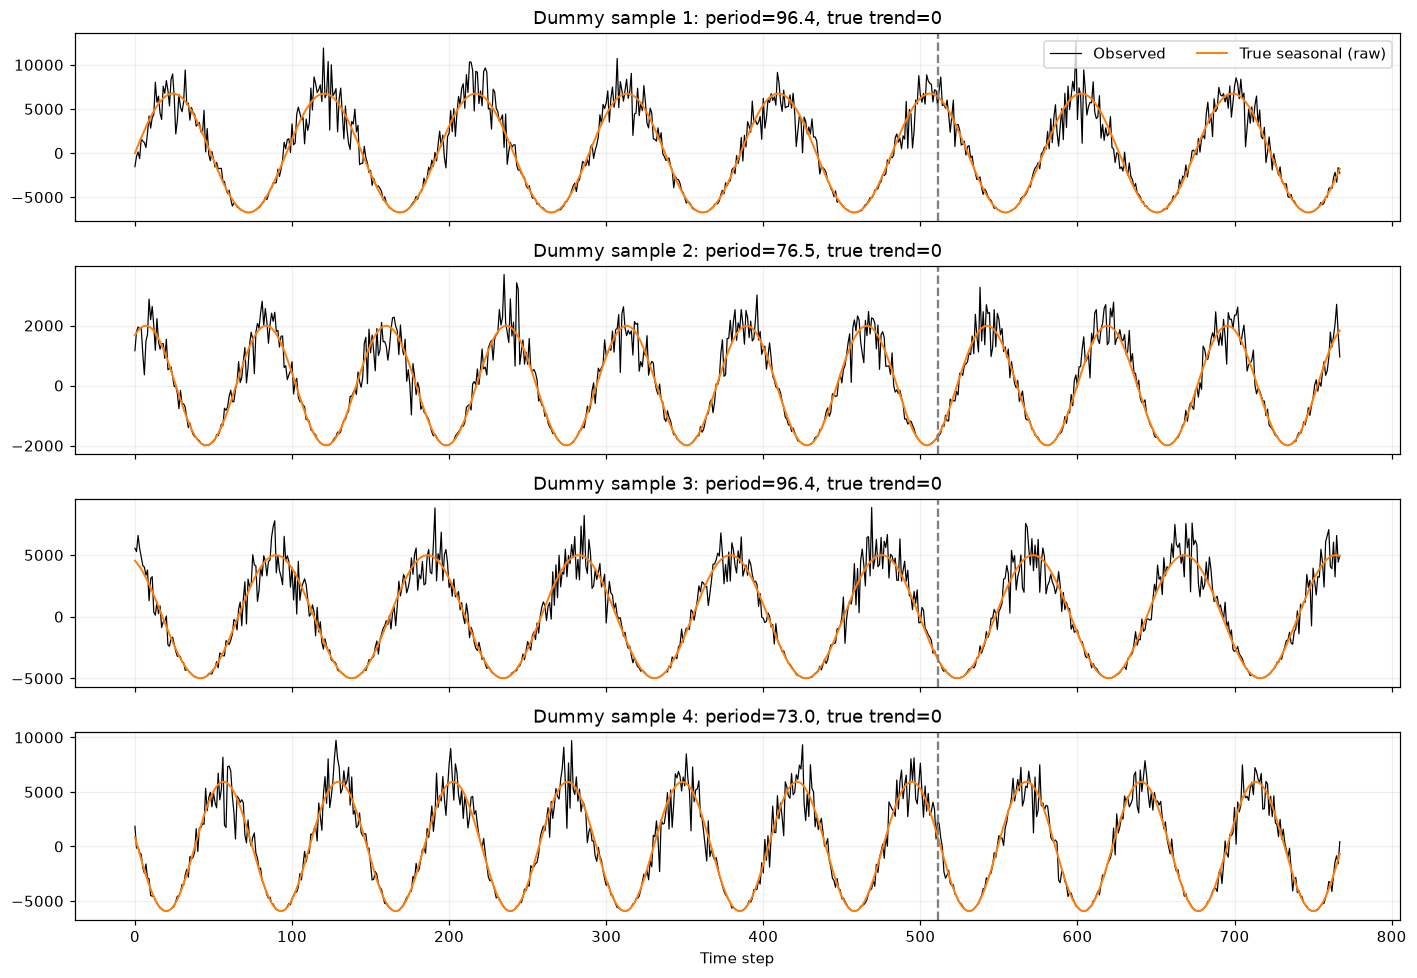

In [2]:
def make_dummy(n, data_seed, global_seed):
    # DummyRandomDataset.seed фиксирует только randn шума; randint частот/масштабов
    # использует глобальный RNG. Фиксируем оба источника и сохраняем внешний RNG.
    with torch.random.fork_rng(devices=[]):
        torch.manual_seed(global_seed)
        return DummyRandomDataset(num_samples=n, context_len=T, pred_len=H, seed=data_seed)

train_ds = make_dummy(N_TRAIN, DATA_SEED, SEED + 10)
val_ds = make_dummy(N_VAL, DATA_SEED + 1, SEED + 20)
eval_seed = SEED + 30
eval_ds = make_dummy(4, DATA_SEED, eval_seed)

# Восстанавливаем известную чистую синусоиду, повторяя randint исходного генератора.
# Сам наблюдаемый ряд берём именно из DummyRandomDataset, а не из копии класса.
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(eval_seed)
    angular_span = torch.randint(20, 70, (4, 1))
    amplitude = torch.randint(1, 10000, (4, 1))
phase = torch.linspace(0, 1, T + H)[None, :] * angular_span + torch.arange(4)[:, None]
sine = torch.sin(phase)
clean_raw = sine * amplitude
noise_std_raw = (sine + 1) * 0.15 * amplitude
noise_draw = torch.randn(4, T + H, generator=torch.Generator().manual_seed(DATA_SEED))
observed_raw = torch.cat([eval_ds.context, eval_ds.target], dim=1)
expected_raw = (sine + noise_draw * (sine + 1) * 0.15) * amplitude
# Проверяем replay формулы и полную воспроизводимость данных.
torch.testing.assert_close(observed_raw, expected_raw, rtol=0, atol=0)
torch.testing.assert_close(eval_ds.context, make_dummy(4, DATA_SEED, eval_seed).context,
                           rtol=0, atol=0)
truth_raw = {"trend": torch.zeros_like(clean_raw), "seasonal": clean_raw,
             "noise": observed_raw - clean_raw}
periods = (T + H - 1) * 2 * np.pi / angular_span.squeeze(1).numpy()
display(pd.DataFrame({"sample": np.arange(1, 5), "period_steps": periods,
                      "amplitude": amplitude.squeeze(1).numpy()}))

model_kwargs = {key: getattr(args, key) for key in inspect.signature(DecoVAEFMLightning.__init__).parameters
                if key != "self" and hasattr(args, key)}
module = DecoVAEFMLightning(**model_kwargs).to(DEVICE)
initial_state = deepcopy(module.state_dict())
initial_weights = torch.softmax(module.model.decomposition.weights.detach(), 0).cpu().numpy()
x_raw = eval_ds.context.to(DEVICE)
y_raw = eval_ds.target.to(DEVICE)
x_mean, x_std = module._get_normalization_stats(x_raw)
x_norm = module._normalize(x_raw, x_mean, x_std)
y_norm = module._normalize(y_raw, x_mean, x_std)
full_norm = torch.cat([x_norm, y_norm], dim=1).cpu()

def encoded_components(core, x):
    core.eval()
    with torch.inference_mode():
        enc = core.encode(x.to(next(core.parameters()).device))
        result = {"trend": enc["target_trend"].cpu(), "seasonal": enc["target_seasonal"].cpu()}
        result["noise"] = x.detach().cpu() - result["trend"] - result["seasonal"]
    torch.testing.assert_close(sum(result.values()), x.detach().cpu(), rtol=1e-5, atol=2e-6)
    return result

initial_encoded = encoded_components(module.model, x_norm)

# Аддитивный oracle в нормализованной шкале строим телескопически:
# F(trend) + [F(trend+seasonal)-F(trend)] + [F(x)-F(trend+seasonal)] = F(x).
# Это явно выбранный порядок, а не единственная "истинная" декомпозиция после asinh.
def normalized_oracle(raw_parts, mean, std):
    raw_t = raw_parts["trend"].to(DEVICE)
    raw_s = raw_parts["seasonal"].to(DEVICE)
    raw_n = raw_parts["noise"].to(DEVICE)
    f_t = module._normalize(raw_t, mean, std)
    f_ts = module._normalize(raw_t + raw_s, mean, std)
    f_all = module._normalize(raw_t + raw_s + raw_n, mean, std)
    return {"trend": f_t.cpu(), "seasonal": (f_ts-f_t).cpu(), "noise": (f_all-f_ts).cpu()}

oracle = normalized_oracle(truth_raw, x_mean, x_std)
torch.testing.assert_close(sum(oracle.values()), full_norm, rtol=1e-5, atol=2e-6)

fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(observed_raw[i], color="black", lw=0.8, label="Observed")
    ax.plot(clean_raw[i], color="tab:orange", lw=1.3, label="True seasonal (raw)")
    ax.axvline(T - 0.5, color="gray", ls="--")
    ax.set_title(f"Dummy sample {i+1}: period={periods[i]:.1f}, true trend=0")
axes[0].legend(ncol=2)
axes[-1].set_xlabel("Time step")
fig.tight_layout()
plt.show()

## Повтор обучения актуальной модели

Используем `DecoVAEFMLightning.training_step`, её текущую нормализацию, `_elbo_losses`
и `configure_optimizers` через `L.Trainer.fit`. Архитектура и loss не изменяются.
В отличие от старого ноутбука CPU/CUDA выбираются автоматически; отключены MLflow,
внешние логгеры, графики callback и early stopping, чтобы действительно закончить 30 эпох.
Train, validation и четыре диагностических ряда имеют разные seed генерации частот/масштабов.
Контрольные кейсы далее не участвуют в обучении.

Epoch  1: val_loss=1.5196, val_recon_loss=-0.2621, val_forecast_loss=1.2824, val_kl_loss=0.4994
Epoch  5: val_loss=0.9483, val_recon_loss=-0.5014, val_forecast_loss=1.1047, val_kl_loss=0.3451
Epoch 10: val_loss=-0.2573, val_recon_loss=-0.7115, val_forecast_loss=0.0497, val_kl_loss=0.4045
Epoch 15: val_loss=-0.6826, val_recon_loss=-0.7678, val_forecast_loss=-0.3010, val_kl_loss=0.3862
Epoch 20: val_loss=-0.8171, val_recon_loss=-0.7808, val_forecast_loss=-0.3912, val_kl_loss=0.3550
Epoch 25: val_loss=-0.0988, val_recon_loss=-0.1005, val_forecast_loss=-0.3248, val_kl_loss=0.3265
Epoch 30: val_loss=-0.9252, val_recon_loss=-0.8212, val_forecast_loss=-0.4156, val_kl_loss=0.3115
Elapsed: 74.1s; model source: /Users/andrew/Desktop/skoltech/DecoVAE_fm_project/decovaefm/models/decovae_fm.py


/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/andrew/miniconda3/lib/python3.13/site-packages/lightning/pytorch/loops/fit_loop.py:534: Found 93 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


,kernel,initial_weight,trained_weight
0,5,0.276684,0.274390
1,9,0.224751,0.226631
2,13,0.249797,0.258444
3,25,0.248768,0.240535


,epoch,val_loss,val_recon_loss,val_forecast_loss,val_kl_loss
25,26,-0.862213,-0.828517,-0.367654,0.333957
26,27,-0.911006,-0.789766,-0.447241,0.326001
27,28,-0.925434,-0.831564,-0.415455,0.321585
28,29,-0.881448,-0.762295,-0.439006,0.319853
29,30,-0.925249,-0.821171,-0.415557,0.311480


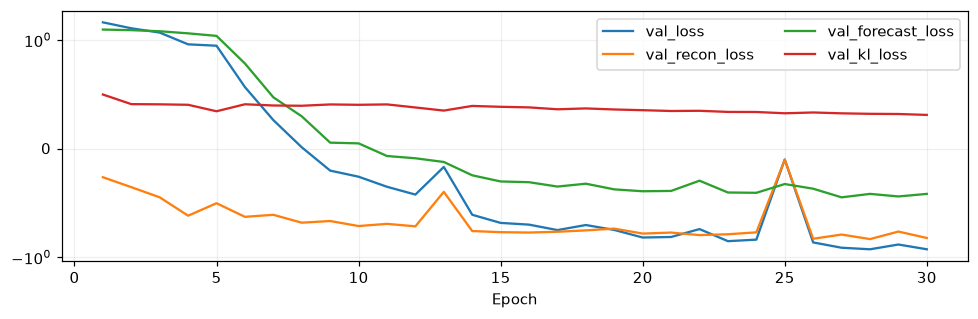

In [3]:
class EpochHistory(L.Callback):
    def __init__(self):
        self.rows = []
    def on_validation_epoch_end(self, trainer, pl_module):
        if trainer.sanity_checking:
            return
        row = {"epoch": trainer.current_epoch + 1}
        for key in ["val_loss", "val_recon_loss", "val_forecast_loss", "val_kl_loss"]:
            value = trainer.callback_metrics.get(key)
            if value is not None:
                row[key] = float(value.detach().cpu())
        self.rows.append(row)
        if row["epoch"] == 1 or row["epoch"] % 5 == 0:
            print(f"Epoch {row['epoch']:2d}: " + ", ".join(f"{k}={v:.4f}" for k,v in row.items() if k != "epoch"))

history_cb = EpochHistory()
started = time.perf_counter()
if CHECKPOINT_PATH is None:
    train_loader = DataLoader(train_ds, batch_size=args.batch_size, shuffle=True, num_workers=0,
                              generator=torch.Generator().manual_seed(SEED + 40))
    val_loader = DataLoader(val_ds, batch_size=args.batch_size, shuffle=False, num_workers=0)
    L.seed_everything(SEED + 50, workers=True)
    trainer = L.Trainer(max_epochs=args.epochs, accelerator=args.accelerator, devices=1,
                        logger=False, enable_checkpointing=False, enable_progress_bar=False,
                        enable_model_summary=False, num_sanity_val_steps=0,
                        gradient_clip_val=None, callbacks=[history_cb])
    trainer.fit(module, train_loader, val_loader)
    if SAVE_CHECKPOINT:
        checkpoint_out = ROOT / "outputs" / "decomposition_reproduction" / "current.ckpt"
        checkpoint_out.parent.mkdir(parents=True, exist_ok=True)
        trainer.save_checkpoint(checkpoint_out)
        print("Saved", checkpoint_out)
else:
    checkpoint_in = Path(CHECKPOINT_PATH).expanduser()
    if not checkpoint_in.is_absolute():
        checkpoint_in = ROOT / checkpoint_in
    if not checkpoint_in.is_file():
        raise FileNotFoundError(checkpoint_in)
    # Загружаем только доверенный локальный Lightning checkpoint.
    module = DecoVAEFMLightning.load_from_checkpoint(checkpoint_in, map_location=DEVICE).to(DEVICE)
    provenance["checkpoint_sha256"] = hashlib.sha256(checkpoint_in.read_bytes()).hexdigest()
    if module.model.decomposition.kernels != args.kernels:
        raise ValueError("Для сравнения до/после укажите kernels checkpoint в конфигурации эксперимента.")
    print("Loaded checkpoint hyperparameters:", dict(module.hparams))
module.eval()
module.num_samples = MC_SAMPLES
assert inspect.getfile(type(module.model)).startswith(str(ROOT / "decovaefm"))
print(f"Elapsed: {time.perf_counter()-started:.1f}s; model source: {inspect.getfile(type(module.model))}")
trained_encoded = encoded_components(module.model, x_norm)
final_weights = torch.softmax(module.model.decomposition.weights.detach(), 0).cpu().numpy()
display(pd.DataFrame({"kernel": args.kernels if CHECKPOINT_PATH is None else module.model.decomposition.kernels,
                      "initial_weight": initial_weights, "trained_weight": final_weights}))
history = pd.DataFrame(history_cb.rows)
if len(history):
    display(history.tail())
    fig, ax = plt.subplots(figsize=(9, 3))
    for key in ["val_loss", "val_recon_loss", "val_forecast_loss", "val_kl_loss"]:
        ax.plot(history.epoch, history[key], label=key)
    ax.set_yscale("symlog", linthresh=1)
    ax.set_xlabel("Epoch")
    ax.legend(ncol=2)
    fig.tight_layout()
    plt.show()

## Декомпозиция входа: до / после обучения

`season_to_trend_gain` — коэффициент проекции ошибки тренда на известную сезонность
после вычитания среднего. Значение около 1 означает, что практически вся её форма
попала в тренд. `seasonal_gain` и `residual_season_gain` измеряют проекции двух других
ветвей на ту же компоненту. Это коэффициенты проекции, не вероятности и не доли энергии.

`*_rmse_over_signal_rms` делит RMSE каждой компоненты на RMS полного нормализованного
контекста: метрика определена и для нулевого тренда. Oracle после asinh использует
описанный выше порядок, поэтому количественные выводы отдельно проверяем на
линейных аддитивных контролях.

,stage,sample,season_to_trend_gain,seasonal_gain,residual_season_gain,trend_rmse_over_signal_rms,seasonal_rmse_over_signal_rms,noise_rmse_over_signal_rms,noise_correlation
0,before_training,1,0.9516,0.0250,0.0122,0.9405,0.9668,0.1376,0.8139
1,before_training,2,0.9272,0.0433,0.0131,0.9195,0.9532,0.1375,0.8086
2,before_training,3,0.9496,0.0261,0.0146,0.9359,0.9636,0.1294,0.8258
3,before_training,4,0.9241,0.0628,0.0008,0.9140,0.9304,0.1294,0.8243
4,after_training,1,0.9522,0.0245,0.0121,0.9411,0.9673,0.1343,0.8240
5,after_training,2,0.9281,0.0426,0.0129,0.9204,0.9539,0.1374,0.8088
6,after_training,3,0.9502,0.0257,0.0143,0.9366,0.9640,0.1293,0.8260
7,after_training,4,0.9251,0.0619,0.0008,0.9149,0.9314,0.1293,0.8245


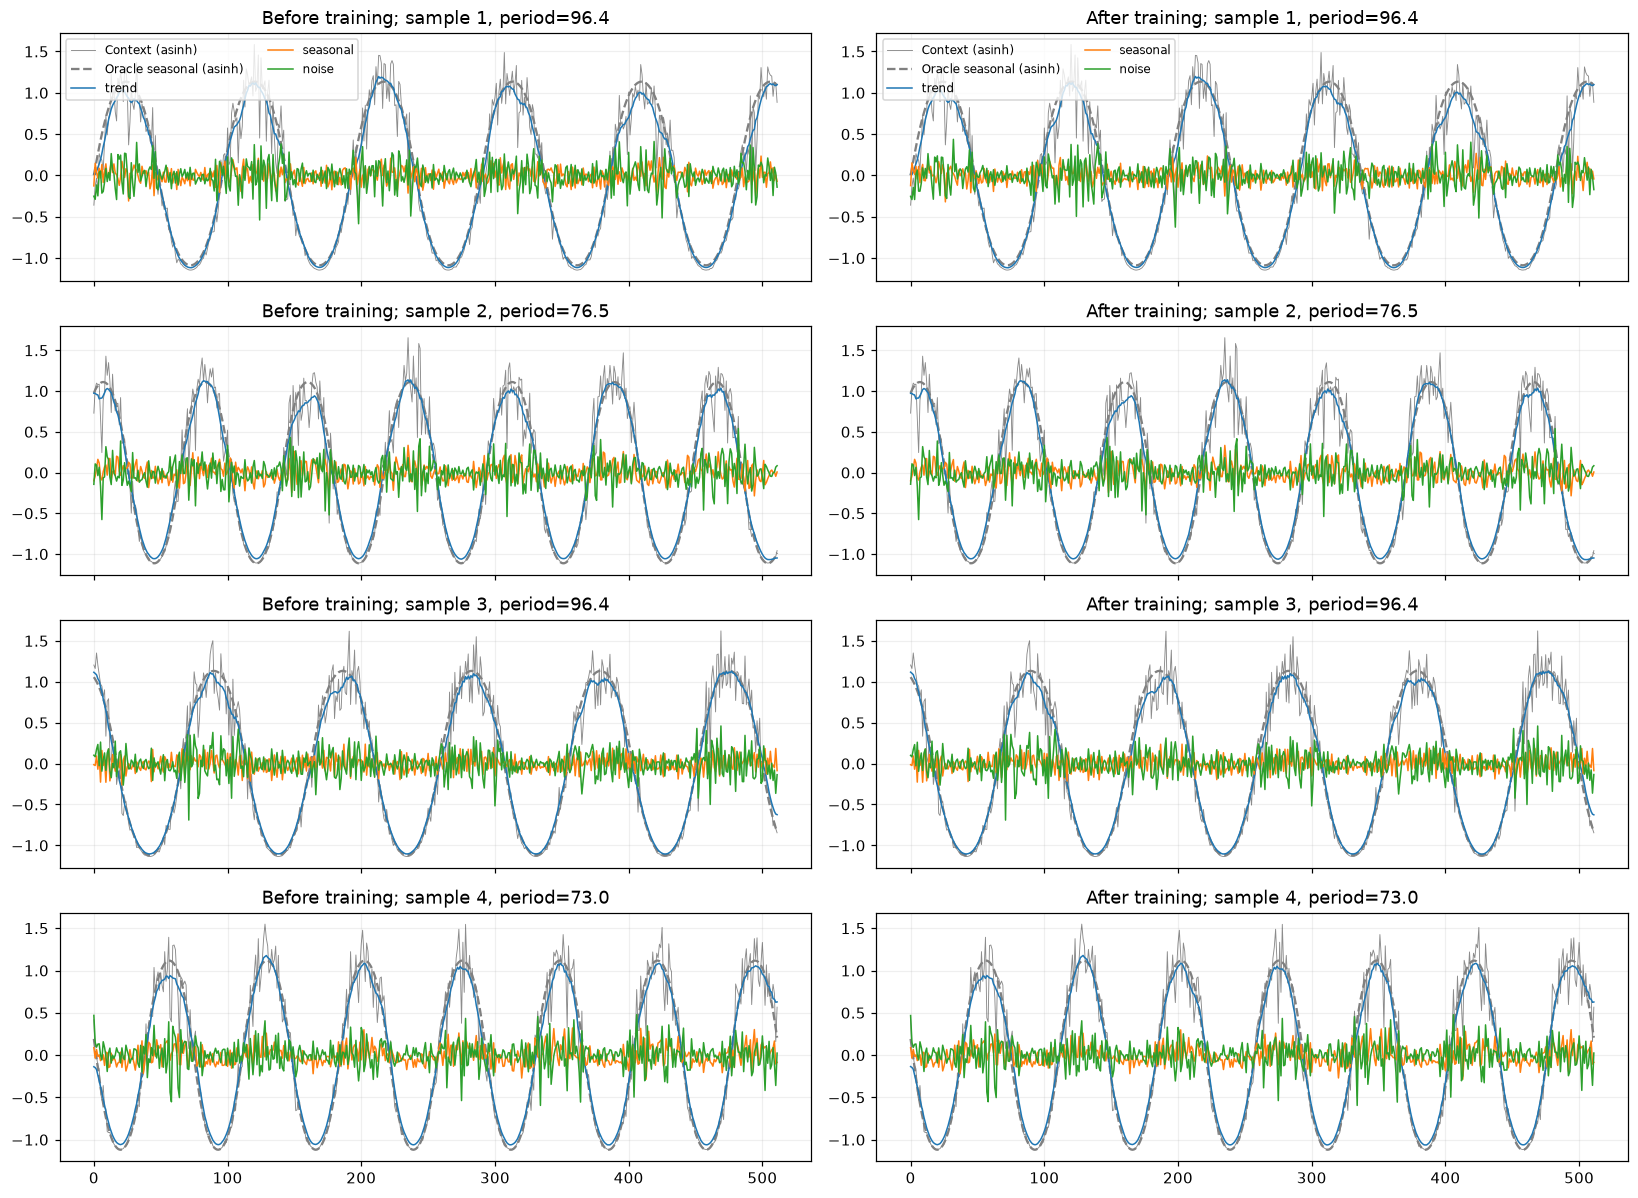

In [4]:
def rms(x):
    return float(torch.sqrt(torch.mean(x.float() ** 2)))

def gain(estimate, reference):
    a = estimate.float() - estimate.float().mean()
    b = reference.float() - reference.float().mean()
    energy = float((b*b).sum())
    return float((a*b).sum()) / energy if energy > 1e-12 else np.nan

def corr(a, b):
    if rms(a-a.mean()) < 1e-8 or rms(b-b.mean()) < 1e-8:
        return np.nan
    return float(np.corrcoef(a.numpy(), b.numpy())[0, 1])

def component_metrics(components, truth, signal, stage):
    rows = []
    for i in range(signal.shape[0]):
        scale = max(rms(signal[i]), 1e-8)
        true_s = truth["seasonal"][i, :signal.shape[1]]
        true_t = truth["trend"][i, :signal.shape[1]]
        row = {"stage": stage, "sample": i+1,
               "season_to_trend_gain": gain(components["trend"][i]-true_t, true_s),
               "seasonal_gain": gain(components["seasonal"][i], true_s),
               "residual_season_gain": gain(components["noise"][i], true_s)}
        for name in ["trend", "seasonal", "noise"]:
            reference = truth[name][i, :signal.shape[1]]
            row[name+"_rmse_over_signal_rms"] = rms(components[name][i]-reference) / scale
        row["noise_correlation"] = corr(components["noise"][i], truth["noise"][i, :signal.shape[1]])
        rows.append(row)
    return pd.DataFrame(rows)

before_table = component_metrics(initial_encoded, oracle, x_norm.cpu(), "before_training")
after_table = component_metrics(trained_encoded, oracle, x_norm.cpu(), "after_training")
dummy_metrics = pd.concat([before_table, after_table], ignore_index=True)
display(dummy_metrics.round(4))

fig, axes = plt.subplots(4, 2, figsize=(15, 11), sharex=True)
for i in range(4):
    for j, (title, result) in enumerate([("Before training", initial_encoded), ("After training", trained_encoded)]):
        ax = axes[i, j]
        ax.plot(x_norm[i].cpu(), color="black", lw=0.6, alpha=0.45, label="Context (asinh)")
        ax.plot(oracle["seasonal"][i, :T], color="gray", ls="--", label="Oracle seasonal (asinh)")
        for name, color in [("trend", "tab:blue"), ("seasonal", "tab:orange"), ("noise", "tab:green")]:
            ax.plot(result[name][i], color=color, lw=1, label=name)
        ax.set_title(f"{title}; sample {i+1}, period={periods[i]:.1f}")
axes[0, 0].legend(ncol=2, fontsize=8)
axes[0, 1].legend(ncol=2, fontsize=8)
fig.tight_layout()
plt.show()

## Выходы декодеров и вероятностный прогноз

Как в исходной ячейке, декодируем средние латентных распределений временной подменой
`reparameterize`, с автоматическим восстановлением через context manager. Это
диагностический forward; обычный forward остаётся стохастическим даже в `.eval()`.
Здесь `decoded_std` — положительный масштаб условной Gaussian-модели наблюдения,
а `x − decoded_trend − decoded_seasonal` — ошибка её среднего. Ни то, ни другое
не является отдельным выходом декодера шумовой реализации.

Квантили следующего графика получаем штатным `predict_step`: он семплирует и латенты,
и шум наблюдения, затем применяет обратный `sinh`. Компоненты отдельно не денормализуем:
`sinh(a+b)` не равно `sinh(a)+sinh(b)`.

,stage,sample,season_to_trend_gain,seasonal_gain,residual_season_gain,trend_rmse_over_signal_rms,seasonal_rmse_over_signal_rms,residual_rmse_over_signal_rms,residual_noise_correlation,recon_rmse,forecast_rmse,seasonal_to_trend_rms_ratio
0,decoded_means_residual,1,0.9959,0.0,-0.0071,0.9836,0.9855,0.0705,0.9548,0.1835,0.2194,0.0
1,decoded_means_residual,2,0.9936,0.0,-0.0100,0.9856,0.9889,0.0770,0.9458,0.1879,0.2160,0.0
2,decoded_means_residual,3,0.9915,0.0,-0.0013,0.9767,0.9832,0.0631,0.9621,0.1841,0.1949,0.0
3,decoded_means_residual,4,0.9920,-0.0,-0.0043,0.9805,0.9859,0.0700,0.9543,0.1829,0.2321,0.0


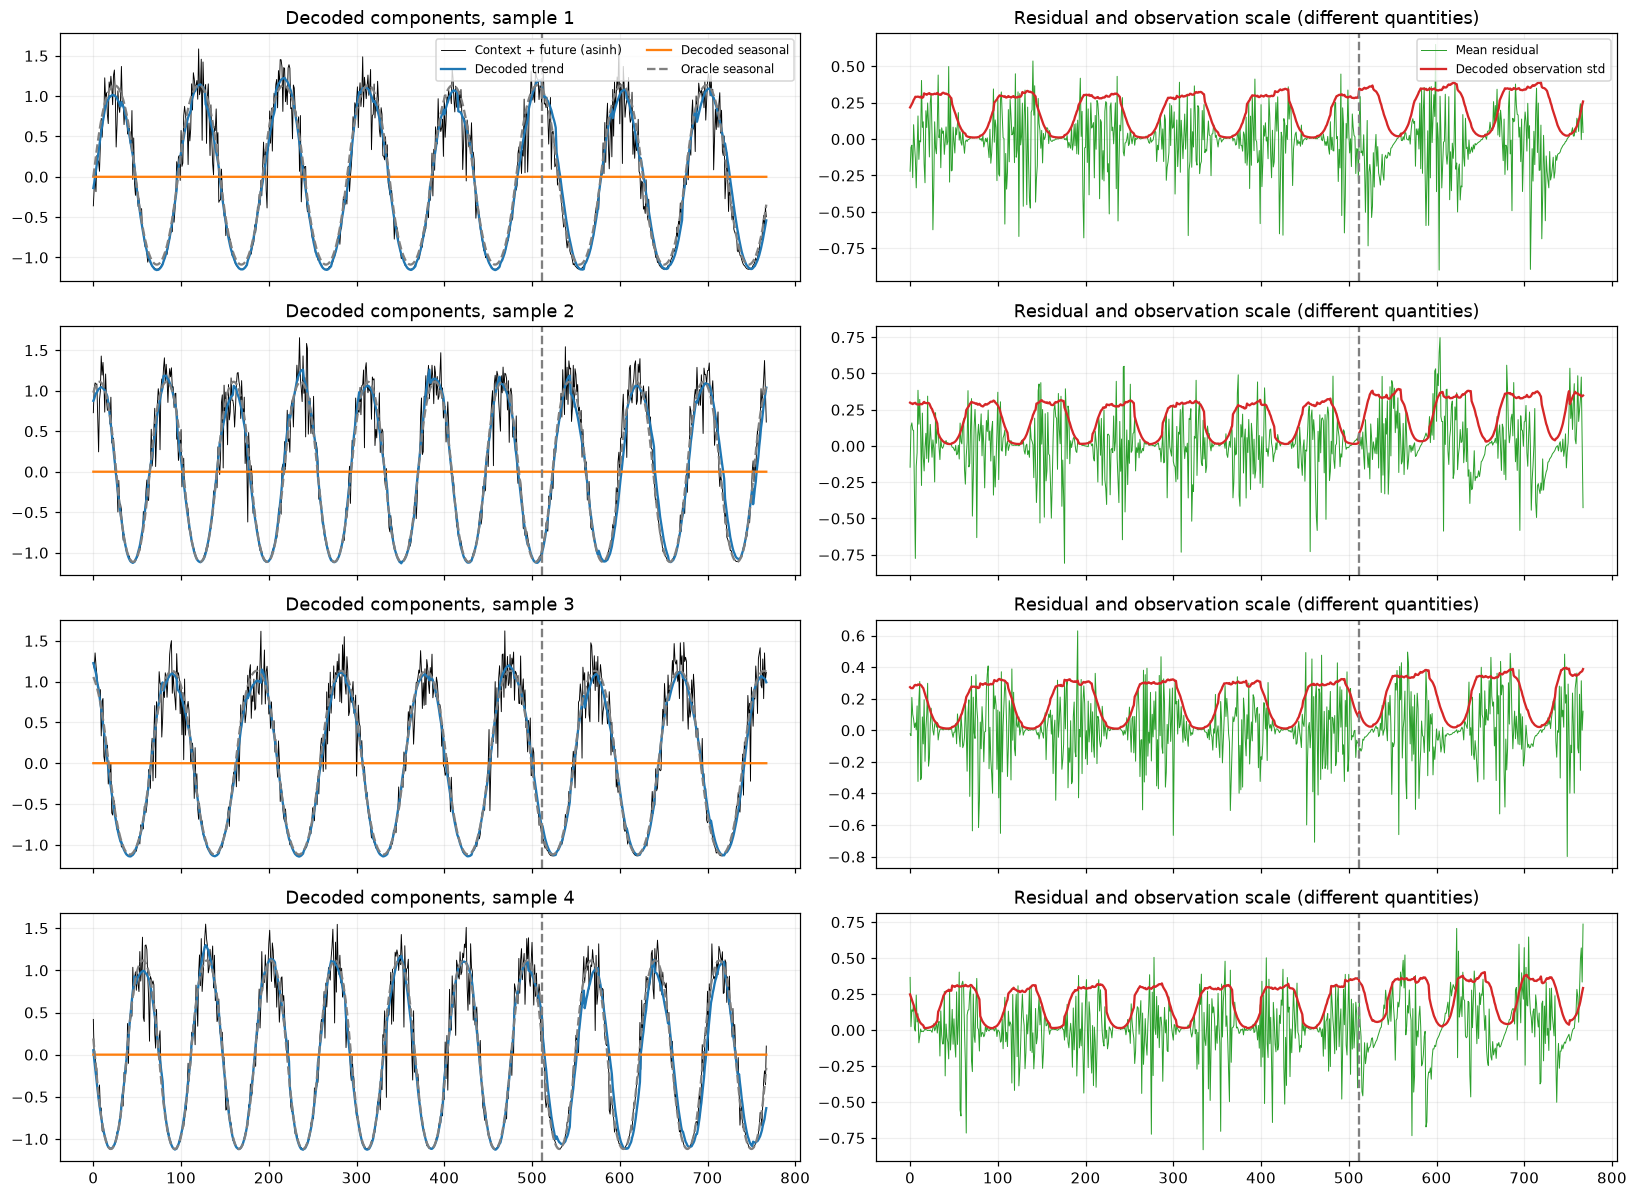

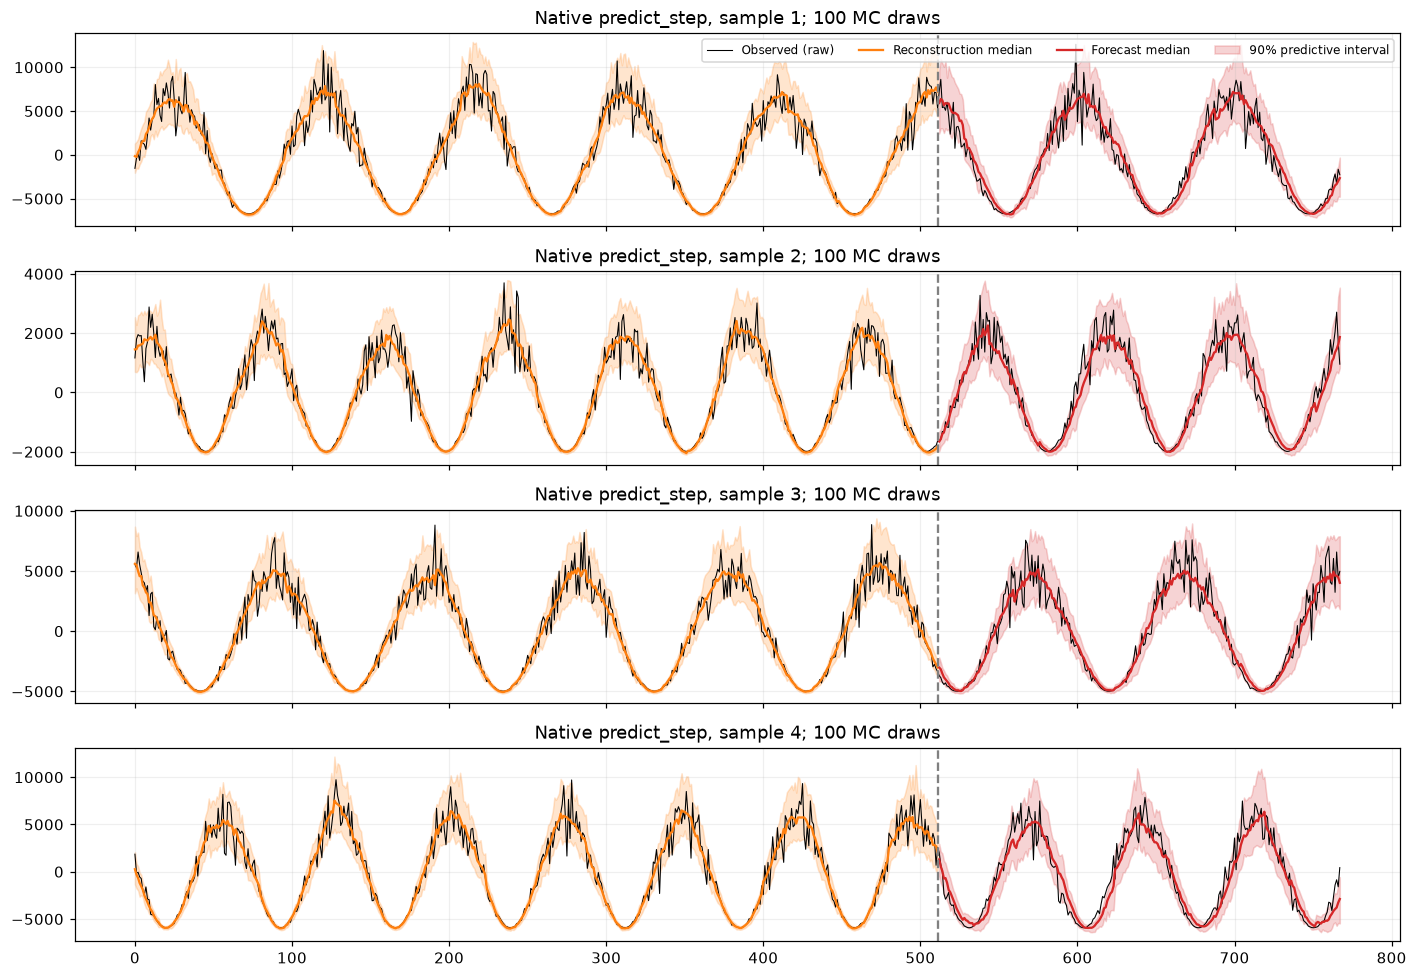

,sample,forecast_rmse_raw,coverage_90
0,1,1400.9661,0.9023
1,2,424.8282,0.8828
2,3,1008.7690,0.9414
3,4,1288.5811,0.8008


In [5]:
with torch.inference_mode(), patch.object(module.model, "reparameterize", side_effect=lambda mu, logvar: mu):
    out = {k: v.cpu() for k,v in module.model(x_norm, pred_len=H).items()}
decoded = {"trend": out["decoded_trend"][:, :T], "seasonal": out["decoded_seasonal"][:, :T]}
decoded["noise"] = x_norm.cpu() - decoded["trend"] - decoded["seasonal"]
# В таблице noise означает residual среднего, а не выход noise decoder.
decoder_metrics = component_metrics(decoded, oracle, x_norm.cpu(), "decoded_means_residual")
decoder_metrics = decoder_metrics.rename(columns={"noise_correlation": "residual_noise_correlation",
                                                 "noise_rmse_over_signal_rms": "residual_rmse_over_signal_rms"})
decoder_metrics["recon_rmse"] = [rms(out["recon_mu"][i]-full_norm[i, :T]) for i in range(4)]
decoder_metrics["forecast_rmse"] = [rms(out["forecast_mu"][i]-full_norm[i, T:]) for i in range(4)]
decoder_metrics["seasonal_to_trend_rms_ratio"] = [rms(out["decoded_seasonal"][i])/max(rms(out["decoded_trend"][i]), 1e-8) for i in range(4)]
display(decoder_metrics.round(4))

fig, axes = plt.subplots(4, 2, figsize=(15, 11), sharex=True)
for i in range(4):
    ax = axes[i, 0]
    ax.plot(full_norm[i], color="black", lw=0.6, label="Context + future (asinh)")
    ax.plot(out["decoded_trend"][i], color="tab:blue", label="Decoded trend")
    ax.plot(out["decoded_seasonal"][i], color="tab:orange", label="Decoded seasonal")
    ax.plot(oracle["seasonal"][i], color="gray", ls="--", label="Oracle seasonal")
    ax.set_title(f"Decoded components, sample {i+1}")
    ax = axes[i, 1]
    ax.plot(full_norm[i]-out["decoded_trend"][i]-out["decoded_seasonal"][i],
            color="tab:green", lw=0.65, label="Mean residual")
    ax.plot((0.5*out["decoded_logvar"][i]).exp(), color="tab:red", label="Decoded observation std")
    ax.set_title("Residual and observation scale (different quantities)")
    for ax in axes[i]:
        ax.axvline(T-0.5, color="gray", ls="--")
axes[0, 0].legend(ncol=2, fontsize=8)
axes[0, 1].legend(fontsize=8)
fig.tight_layout()
plt.show()

with torch.random.fork_rng(devices=[torch.cuda.current_device()] if DEVICE == "cuda" else []):
    torch.manual_seed(SEED + 60)
    with torch.inference_mode():
        prediction = module.predict_step((x_raw, y_raw), batch_idx=0)
recon_q = torch.quantile(prediction["recon_samples"].cpu(), torch.tensor([0.05, 0.5, 0.95]), dim=1)
forecast_q = torch.quantile(prediction["forecast_samples"].cpu(), torch.tensor([0.05, 0.5, 0.95]), dim=1)
fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
forecast_rows = []
for i, ax in enumerate(axes):
    ax.plot(observed_raw[i], color="black", lw=0.7, label="Observed (raw)")
    ax.plot(np.arange(T), recon_q[1, i], color="tab:orange", label="Reconstruction median")
    ax.fill_between(np.arange(T), recon_q[0, i], recon_q[2, i], color="tab:orange", alpha=0.2)
    ax.plot(np.arange(T, T+H), forecast_q[1, i], color="tab:red", label="Forecast median")
    ax.fill_between(np.arange(T, T+H), forecast_q[0, i], forecast_q[2, i],
                    color="tab:red", alpha=0.2, label="90% predictive interval")
    ax.axvline(T-0.5, color="gray", ls="--")
    ax.set_title(f"Native predict_step, sample {i+1}; {MC_SAMPLES} MC draws")
    future = observed_raw[i, T:]
    forecast_rows.append({"sample": i+1,
                         "forecast_rmse_raw": rms(forecast_q[1,i]-future),
                         "coverage_90": float(((future>=forecast_q[0,i]) & (future<=forecast_q[2,i])).float().mean())})
axes[0].legend(ncol=4, fontsize=8)
fig.tight_layout()
plt.show()
forecast_metrics = pd.DataFrame(forecast_rows)
display(forecast_metrics.round(4))

## Контроли с известными аддитивными компонентами

Для этой проверки **только входного оператора** подаём в `core.encode` непосредственно
аддитивные сигналы умеренного масштаба, без нелинейного asinh. Это изолирует смешивание
moving average / top-K FFT и позволяет сравнивать компоненты с точной ground truth.
Это не оценка прогноза обученной модели на исходной шкале и не дополнительное обучение.
Каждый сигнал имеет 512 отсчётов; будущее не используется в encode.

Контроли: короткая и длинная чистые синусоиды; линейный тренд + длинная синусоида
+ гетероскедастический шум; белый шум; синусоида вне FFT-сетки; скачок уровня с сезонностью.

,stage,case,sample,season_to_trend_gain,seasonal_gain,residual_season_gain,trend_rmse_over_signal_rms,seasonal_rmse_over_signal_rms,noise_rmse_over_signal_rms,noise_correlation
0,trained_input_operator,sine_period_16,1,0.3755,0.6245,0.0000,0.3805,0.3766,0.0542,NaN
1,trained_input_operator,sine_period_128,2,0.9789,0.0211,0.0000,0.9791,0.9790,0.0174,NaN
2,trained_input_operator,trend_slow_sine_hetero_noise,3,0.9858,-0.0000,0.0208,0.8329,0.8483,0.1211,0.8242
3,trained_input_operator,white_noise,4,NaN,NaN,NaN,0.3134,0.4649,0.5544,0.8350
4,trained_input_operator,off_grid_sine_period_97,5,0.9633,0.0354,0.0013,0.9636,0.9648,0.0158,NaN
5,trained_input_operator,level_shift_and_sine,6,0.7202,0.2816,0.0000,0.5910,0.5871,0.0726,0.6897


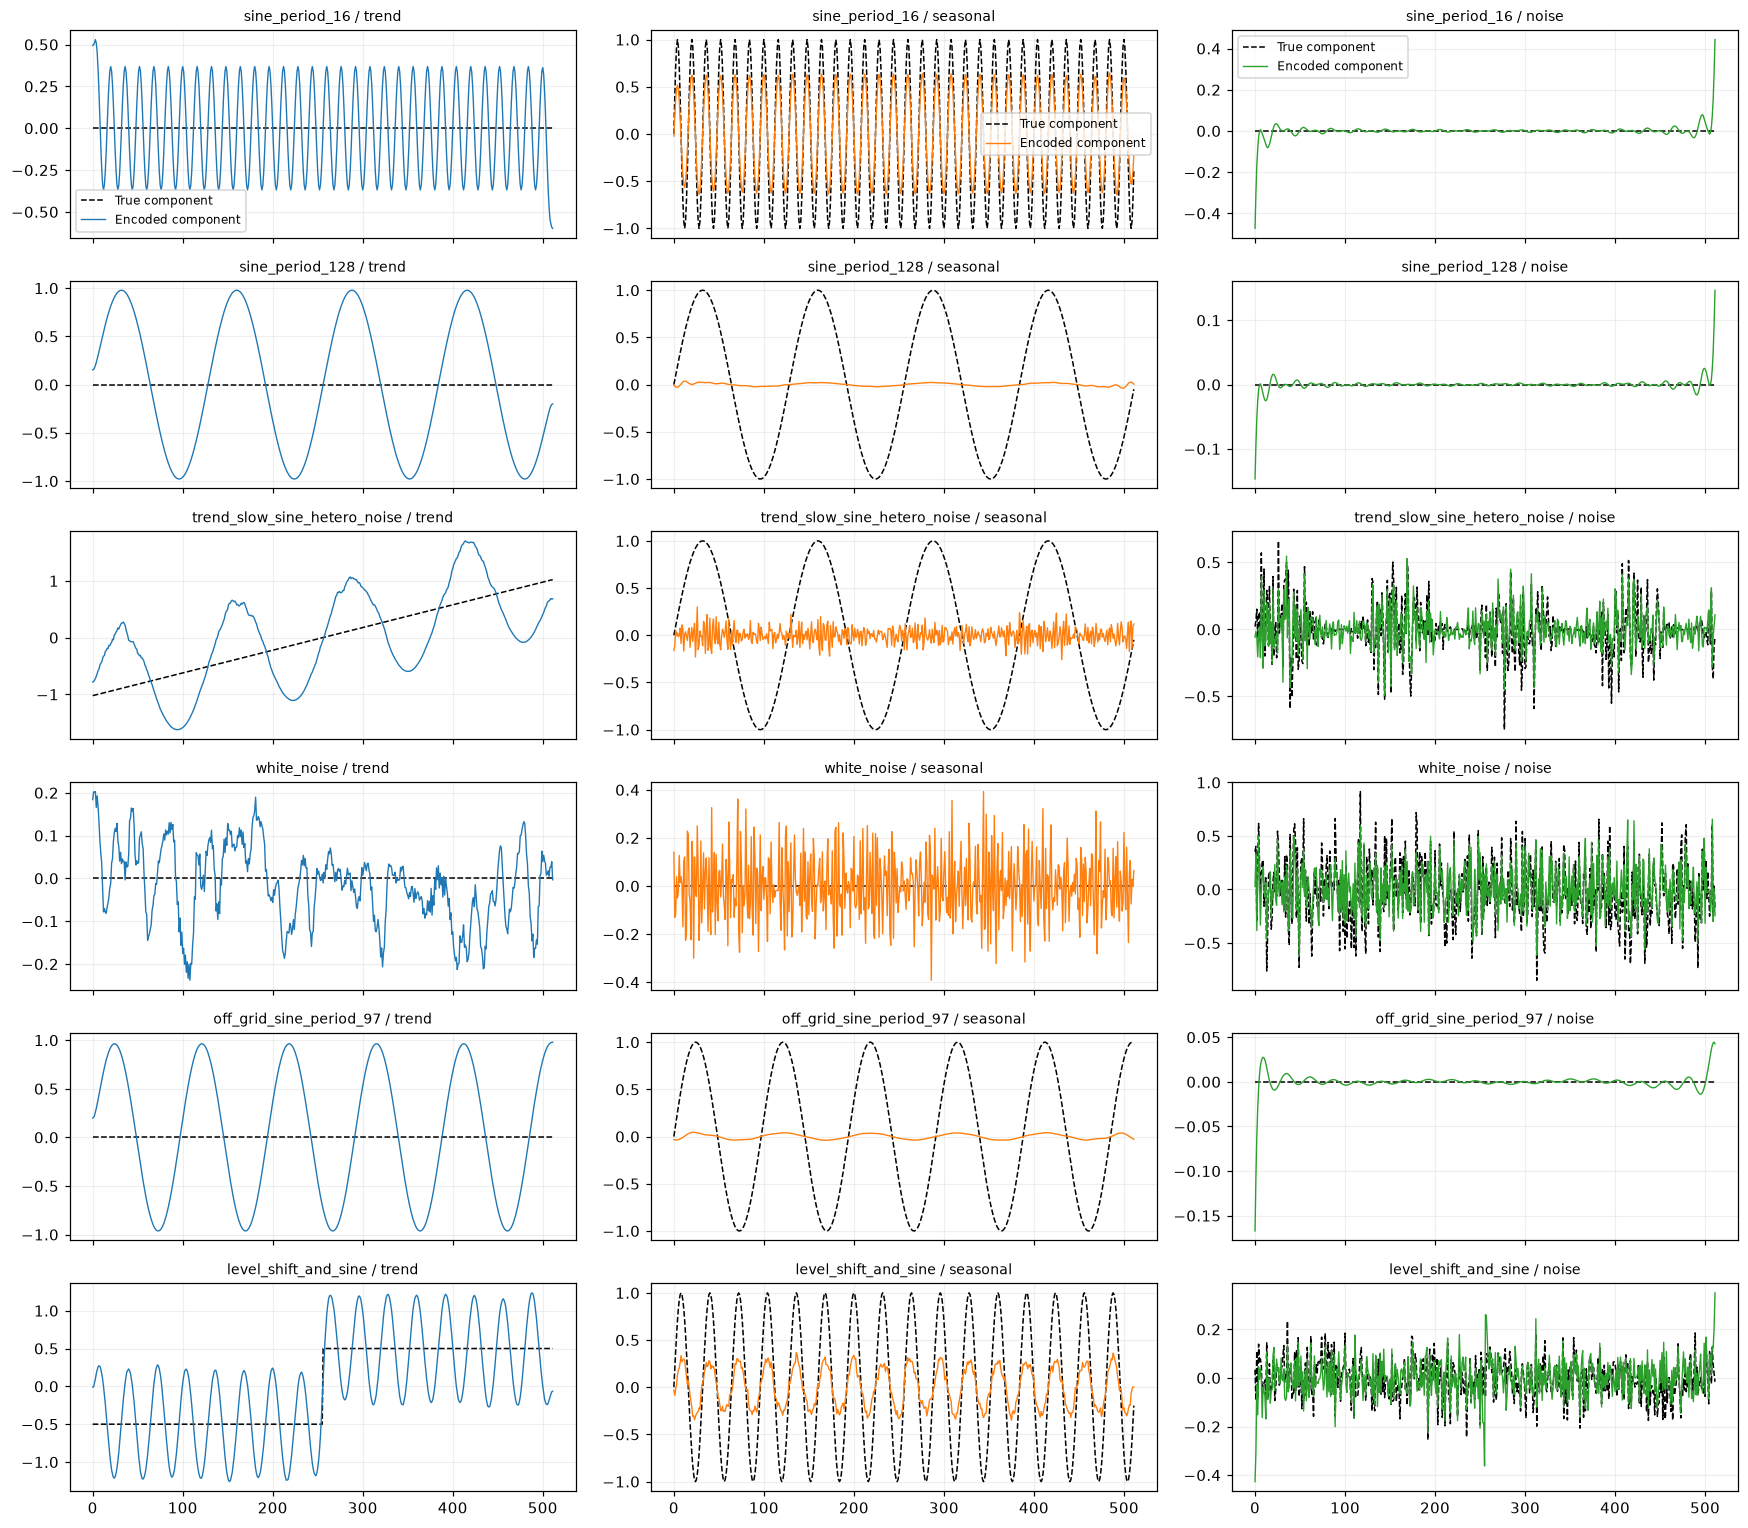

In [6]:
t = torch.arange(T, dtype=torch.float32)
g = torch.Generator().manual_seed(SEED + 70)
zeros = torch.zeros(T)
controls = []
def add_control(name, trend, seasonal, noise):
    controls.append({"name": name, "trend": trend, "seasonal": seasonal, "noise": noise,
                     "signal": trend+seasonal+noise})
add_control("sine_period_16", zeros, torch.sin(2*torch.pi*t/16), zeros)
add_control("sine_period_128", zeros, torch.sin(2*torch.pi*t/128), zeros)
slow_s = torch.sin(2*torch.pi*t/128)
add_control("trend_slow_sine_hetero_noise", 0.004*(t-t.mean()), slow_s,
            torch.randn(T, generator=g)*0.15*(slow_s+1))
add_control("white_noise", zeros, zeros, torch.randn(T, generator=g)*0.3)
add_control("off_grid_sine_period_97", zeros, torch.sin(2*torch.pi*t/97), zeros)
add_control("level_shift_and_sine", (t>=T//2).float()-0.5, torch.sin(2*torch.pi*t/32),
            torch.randn(T, generator=g)*0.08)
control_signal = torch.stack([c["signal"] for c in controls])
control_truth = {name: torch.stack([c[name] for c in controls]) for name in ["trend", "seasonal", "noise"]}
control_encoded = encoded_components(module.model, control_signal)
control_metrics = component_metrics(control_encoded, control_truth, control_signal, "trained_input_operator")
control_metrics.insert(1, "case", [c["name"] for c in controls])
display(control_metrics.round(4))

fig, axes = plt.subplots(len(controls), 3, figsize=(16, 14), sharex=True)
for i, c in enumerate(controls):
    for j, name in enumerate(["trend", "seasonal", "noise"]):
        ax = axes[i,j]
        ax.plot(c[name], color="black", lw=1, ls="--", label="True component")
        ax.plot(control_encoded[name][i], color=["tab:blue", "tab:orange", "tab:green"][j],
                lw=0.9, label="Encoded component")
        ax.set_title(f"{c['name']} / {name}", fontsize=9)
for ax in axes[0]:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Почему длинная сезонность попадает в тренд

Для центрированного moving average длины k внутренний участок синусоиды периода P
умножается на `sin(pi*k/P) / (k*sin(pi/P))`. Взвешиваем эту величину текущими softmax-весами
`MultiScaleDecomposition`. При P существенно больше всех k коэффициент близок к 1:
такой фильтр сохраняет медленную синусоиду в тренде. Границы отражаются, поэтому
сравнение формулы с измерением проводим вне первых/последних `max(kernels)//2` точек.

Top-K FFT применяется уже к остатку. Он не может вернуть в seasonal ту часть сигнала,
которая до FFT оказалась в trend. Кроме того, top-K может захватывать отдельные
частоты шума и оставлять утечку вне сетки в residual.

,period,trend_gain_interior,analytic_initial_gain,analytic_trained_gain,seasonal_gain_full,noise_gain_full
0,8.0,0.0497,0.0523,0.0497,0.9461,0.0000
1,16.0,0.3687,0.3661,0.3687,0.6245,0.0000
2,32.0,0.7189,0.7151,0.7189,0.2754,0.0000
3,64.0,0.9171,0.9158,0.9171,0.0809,0.0000
4,96.0,0.9620,0.9614,0.9620,0.0357,0.0010
5,128.0,0.9784,0.9780,0.9784,0.0211,0.0000
6,192.0,0.9903,0.9902,0.9903,0.0104,-0.0001
7,256.0,0.9945,0.9945,0.9945,0.0053,0.0000


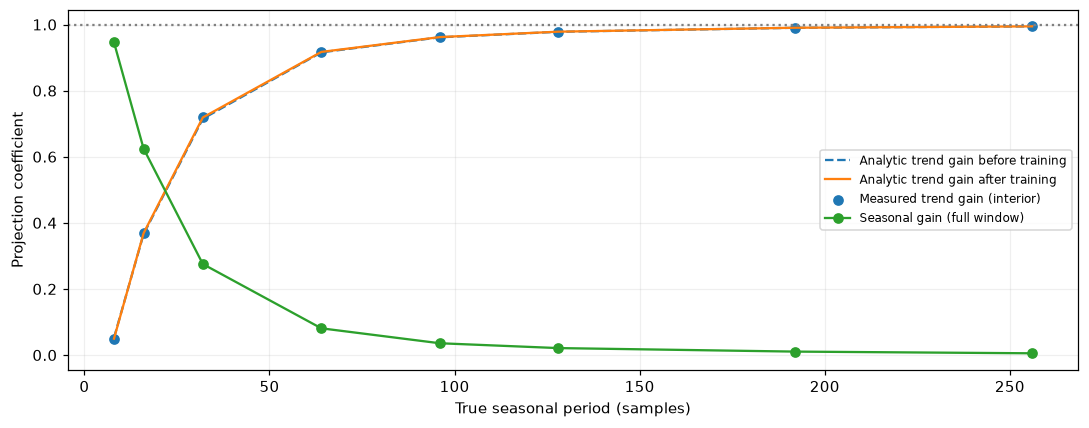

In [7]:
sweep_periods = np.array([8, 16, 32, 64, 96, 128, 192, 256], dtype=float)
sweep_x = torch.stack([torch.sin(2*torch.pi*t/float(p)) for p in sweep_periods])
sweep_encoded = encoded_components(module.model, sweep_x)
kernels = np.asarray(module.model.decomposition.kernels, dtype=float)
edge = int(kernels.max())//2
interior = slice(edge, T-edge)
response = np.sin(np.pi*kernels[None,:]/sweep_periods[:,None]) / (kernels[None,:]*np.sin(np.pi/sweep_periods[:,None]))
sweep_rows = []
for i,p in enumerate(sweep_periods):
    sweep_rows.append({"period": p,
                      "trend_gain_interior": gain(sweep_encoded["trend"][i,interior], sweep_x[i,interior]),
                      "analytic_initial_gain": float(response[i]@initial_weights),
                      "analytic_trained_gain": float(response[i]@final_weights),
                      "seasonal_gain_full": gain(sweep_encoded["seasonal"][i], sweep_x[i]),
                      "noise_gain_full": gain(sweep_encoded["noise"][i], sweep_x[i])})
sweep_table = pd.DataFrame(sweep_rows)
display(sweep_table.round(4))
np.testing.assert_allclose(sweep_table.trend_gain_interior, sweep_table.analytic_trained_gain,
                           atol=2e-5, rtol=2e-5)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sweep_table.period, sweep_table.analytic_initial_gain, "--", label="Analytic trend gain before training")
ax.plot(sweep_table.period, sweep_table.analytic_trained_gain, label="Analytic trend gain after training")
ax.scatter(sweep_table.period, sweep_table.trend_gain_interior, color="tab:blue", label="Measured trend gain (interior)")
ax.plot(sweep_table.period, sweep_table.seasonal_gain_full, "o-", label="Seasonal gain (full window)")
ax.axhline(1, color="gray", ls=":")
ax.set_xlabel("True seasonal period (samples)")
ax.set_ylabel("Projection coefficient")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Итоги текущего запуска и проверки

Вывод формируется из полученных чисел; короткий smoke-run не следует интерпретировать
как обученную модель. Декомпозиция точно складывается обратно в контекст, но само по
себе это не доказывает правильное разделение. Качество восстановления полного ряда
также не гарантирует, что декодеры выучили соответствующие физические компоненты.

Контрольные примеры являются стресс-тестом входного оператора. Основная проверка
обученной модели — четыре отложенных Dummy-окна. Выводы одного seed не заменяют
статистическую оценку по нескольким обучениям.

In [8]:
# Проверяем формы, конечность и согласованность штатного forward.
for key in ["decoded_trend", "decoded_seasonal", "decoded_logvar"]:
    assert out[key].shape == (4, T+H), (key, out[key].shape)
    assert torch.isfinite(out[key]).all(), key
torch.testing.assert_close(out["recon_mu"], (out["decoded_trend"]+out["decoded_seasonal"])[:,:T])
torch.testing.assert_close(out["forecast_mu"], (out["decoded_trend"]+out["decoded_seasonal"])[:,T:])
assert prediction["forecast_samples"].shape == (4, MC_SAMPLES, H)
assert torch.isfinite(prediction["forecast_samples"]).all()
assert torch.isfinite(prediction["recon_samples"]).all()
assert "reparameterize" not in module.model.__dict__, "Temporary patch was not restored"
if CHECKPOINT_PATH is None:
    assert len(history) == args.epochs
    assert not all(torch.equal(v, initial_state[k]) for k,v in module.state_dict().items())

leak_before = before_table.season_to_trend_gain.mean()
leak_after = after_table.season_to_trend_gain.mean()
ratio = decoder_metrics.seasonal_to_trend_rms_ratio.mean()
long_case = control_metrics.loc[control_metrics.case == "sine_period_128"].iloc[0]
checks = {
    "profile": RUN_PROFILE,
    "training_epochs": len(history),
    "dummy_mean_season_to_trend_gain_before": float(leak_before),
    "dummy_mean_season_to_trend_gain_after": float(leak_after),
    "decoded_mean_seasonal_to_trend_rms_ratio": float(ratio),
    "pure_sine_period_128_season_to_trend_gain": float(long_case.season_to_trend_gain),
    # Пороги — описательные критерии этого эксперимента, не требования к архитектуре.
    "input_season_leakage_reproduced": bool(leak_after > 0.5),
    "decoder_trend_dominance_observed": bool(ratio < 0.2),
    "finite_outputs_and_additivity_checks": "passed",
}
print(json.dumps(checks, indent=2, ensure_ascii=False))
status = "**Полный повтор обучения**" if RUN_PROFILE == "full" else "**SMOKE: короткий запуск**"
if CHECKPOINT_PATH is not None:
    status = "**Проверка локального checkpoint**"
display(Markdown(
    f"{status}. Средний коэффициент утечки сезонности в тренд на Dummy-окнах: "
    f"**{leak_before:.3f} → {leak_after:.3f}**. "
    f"Отношение RMS seasonal/trend в декодере: **{ratio:.3f}**. "
    f"На чистой синусоиде периода 128 коэффициент попадания в trend: "
    f"**{long_case.season_to_trend_gain:.3f}**. "
    "Сравните эти числа с графиками выше: шумовая ветвь декодера оценивает дисперсию, "
    "а входной residual может содержать часть сезонности."
))

{
  "profile": "full",
  "training_epochs": 30,
  "dummy_mean_season_to_trend_gain_before": 0.9381335555388696,
  "dummy_mean_season_to_trend_gain_after": 0.9389087097723949,
  "decoded_mean_seasonal_to_trend_rms_ratio": 4.267828903355016e-05,
  "pure_sine_period_128_season_to_trend_gain": 0.9789160490036011,
  "input_season_leakage_reproduced": true,
  "decoder_trend_dominance_observed": true,
  "finite_outputs_and_additivity_checks": "passed"
}


<IPython.core.display.Markdown object>